# Hands-on IMV Laboratory: Chroma Key, Filtering, dan Edge Detection
### Study group IMV Laboratory — versi lokal (VSCode / Jupyter)

Modul ini menggabungkan dua hands-on menjadi satu alur: dari **ruang warna dan chroma keying** sampai **konvolusi, filtering, dan edge detection**, lalu ditutup dengan **bonus hapus background** yang memakai semua konsep sebelumnya.

---

### Alur Pembelajaran:
**Bagian 1 — Color Space, Thresholding, dan Background Replacement**
1. Akuisisi citra (webcam atau fallback sintetis), representasi BGR vs RGB
2. Ruang warna HSV dan channel H, S, V
3. Thresholding: `cv2.threshold` (grayscale) vs `cv2.inRange` (HSV)
4. Masking dan operasi bitwise
5. Background replacement dengan `cv2.add`, plus template live chroma key real-time

**Bagian 2 — Filtering dan Edge Detection**
1. Konvolusi 2D manual pakai loop
2. Filtering: mean, Gaussian, median, sharpening
3. Edge detection: Sobel, Prewitt, Laplacian/LoG, Canny
4. Perbandingan akhir

**Bagian 3 — Bonus: Hapus Background** (Otsu, Edge + Contour, GrabCut)

**Bagian 4 — Latihan Praktikan**

---

### Library yang Dipakai:
- **`numpy`**: array citra, padding, batas warna
- **`opencv-python` (`cv2`)**: konversi ruang warna, thresholding, operasi bitwise, filter, Sobel, Canny, GrabCut
- **`matplotlib`**: menampilkan gambar dan perbandingan
- **`scikit-image`**: hanya untuk gambar contoh bawaan (fallback bila tidak ada file gambar)
- **`numba`** (opsional): mempercepat loop manual. Tanpa numba kode tetap jalan (lebih lambat)

```bash
# Perintah instalasi library jika belum terpasang di environment Anda:
pip install numpy opencv-python matplotlib scikit-image numba
```
> **Catatan VSCode:** pilih kernel Python yang sudah berisi library di atas (pojok kanan atas notebook). Letakkan file gambar (mis. `background.jpg`, `h2hjuun.jpg`) di folder yang sama dengan notebook ini.

In [31]:
import os
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# numba opsional: kalau ada, loop manual dikompilasi (jauh lebih cepat)
try:
    from numba import njit
    HAS_NUMBA = True
except ImportError:
    HAS_NUMBA = False

    def njit(*args, **kwargs):  # pengganti kosong: fungsi jalan sebagai Python biasa
        if len(args) == 1 and callable(args[0]):
            return args[0]
        return lambda f: f

print('OpenCV  :', cv2.__version__)
print('numba tersedia:', HAS_NUMBA)

# Resolusi plot agar tampilan tajam
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(42)  # seed supaya hasil noise bisa diulang

OpenCV  : 4.11.0
numba tersedia: True


## 0. Fungsi Bantu Bersama

Satu fungsi `show()` dipakai di seluruh notebook. Ia otomatis mendeteksi jenis citra: **2 dimensi** (grayscale / mask) ditampilkan dengan `cmap='gray'` dan rentang tetap 0-255, **3 dimensi** (RGB) ditampilkan apa adanya. Ingat: Matplotlib mengasumsikan urutan **RGB**, sedangkan OpenCV memakai **BGR**.

In [32]:
def show(images, titles, cols=3, size=(4, 4)):
    """
    Tampilkan kumpulan gambar berdampingan dengan matplotlib.
    - citra 2D (grayscale / mask)  -> cmap='gray', vmin=0, vmax=255
    - citra 3D (RGB)               -> ditampilkan langsung
    """
    n = len(images)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size[0], rows * size[1]))
    axes = np.array(axes).reshape(-1)  # ratakan jadi 1D agar konsisten untuk 1 atau banyak subplot

    for i in range(n):
        img_i = images[i]
        title = titles[i] if i < len(titles) else ''
        if img_i.ndim == 2:
            axes[i].imshow(img_i, cmap='gray', vmin=0, vmax=255)
        else:
            axes[i].imshow(img_i)
        axes[i].set_title(title, fontsize=11, fontweight='bold', pad=8)
        axes[i].axis('off')

    for j in range(n, len(axes)):  # sembunyikan subplot sisa
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()


def to_uint8(a):
    # Clip ke 0-255 lalu ubah ke uint8 (hindari overflow/wrap-around)
    return np.clip(a, 0, 255).astype(np.uint8)


def normalize_to_uint8(a):
    # Skala nilai apa pun (mis. gradien) ke rentang 0-255
    a = a.astype(np.float64)
    a = a - a.min()
    if a.max() > 0:
        a = a / a.max() * 255
    return a.astype(np.uint8)


def psnr(a, b):
    # Makin tinggi makin mirip dengan gambar referensi
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return float('inf') if mse == 0 else 10 * np.log10(255 ** 2 / mse)


def resize_max(a, max_side=256):
    # Perkecil gambar kalau sisi terpanjangnya > max_side (loop manual lambat untuk gambar besar)
    h, w = a.shape[:2]
    scale = max_side / max(h, w)
    if scale >= 1:
        return a
    return cv2.resize(a, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)

---
# BAGIAN 1 — Color Space, Thresholding, dan Background Replacement

## 1.0 Akuisisi Citra dan Gambar Background

### Representasi Citra pada OpenCV:
- **Urutan Channel BGR:** OpenCV membaca citra dalam urutan **BGR (Blue, Green, Red)**, bukan RGB. Citra disimpan sebagai `numpy.ndarray` bertipe `uint8` dengan rentang nilai $0 - 255$. Jika citra BGR langsung ditampilkan dengan Matplotlib (yang mengasumsikan RGB), warna akan tampak terbalik (kulit kebiruan, merah tertukar dengan biru).
- **Alur Kerja Bagian Ini:**
  1. Ambil $1$ frame dari webcam menggunakan `cv2.VideoCapture(0)`, dengan subjek di depan latar satu warna (kain hijau / *green screen*, atau biru).
  2. Siapkan $1$ gambar background pengganti (`background.jpg`).
  3. **Fallback otomatis:** bila webcam / file tidak tersedia, kode membangkitkan citra sintetis berukuran $480 \times 640$ (subjek simulasi di depan background hijau + background pemandangan buatan), sehingga seluruh sel di bawahnya **reproducible** di perangkat apa pun.

In [33]:
SUMBER_FRAME = 'webcam'     # 'webcam' | 'file' | 'sintetis'
FRAME_PATH = 'foto_subjek.jpg'   # dipakai bila SUMBER_FRAME = 'file'
bg_path = 'background.jpg'       # gambar background pengganti

frame = None
if SUMBER_FRAME == 'webcam':
    cap = cv2.VideoCapture(0)
    if cap.isOpened():
        ret, captured_frame = cap.read()
        if ret and captured_frame is not None:
            frame = captured_frame
    cap.release()
elif SUMBER_FRAME == 'file':
    frame = cv2.imread(FRAME_PATH)

[INFO] Berhasil mendapatkan 1 frame.
[INFO] File 'background.jpg' tidak ditemukan. Membuat background pemandangan sintetis...
frame.shape : (480, 640, 3)
frame.dtype : uint8
frame.min() : 0
frame.max() : 255


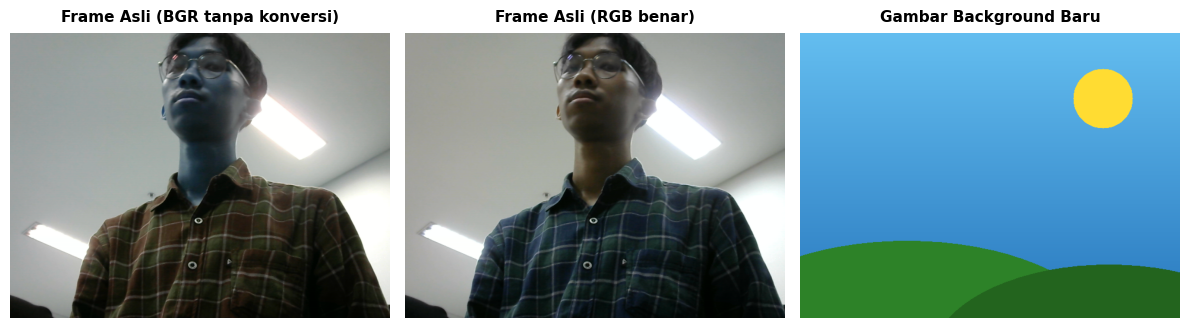

In [34]:
# Fallback: citra sintetis (480, 640, 3) uint8 bila frame belum didapat
if frame is None:
    print("[INFO] Frame tidak tersedia. Menggunakan citra sintetis subjek...")
    frame = np.zeros((480, 640, 3), dtype=np.uint8)
    # Latar hijau green screen (BGR: B=0, G=200, R=0)
    frame[:] = [0, 200, 0]

    # Badan / baju biru (BGR: B=180, G=50, R=50)
    cv2.ellipse(frame, (320, 440), (140, 160), 0, 180, 360, (180, 50, 50), -1)
    # Wajah / warna kulit (BGR: B=140, G=180, R=235)
    cv2.circle(frame, (320, 230), 80, (140, 180, 235), -1)
    # Rambut hitam
    cv2.ellipse(frame, (320, 180), (82, 50), 0, 180, 360, (20, 20, 20), -1)
    # Mata dan senyum
    cv2.circle(frame, (290, 220), 8, (255, 255, 255), -1)
    cv2.circle(frame, (290, 220), 4, (20, 20, 20), -1)
    cv2.circle(frame, (350, 220), 8, (255, 255, 255), -1)
    cv2.circle(frame, (350, 220), 4, (20, 20, 20), -1)
    cv2.ellipse(frame, (320, 260), (30, 15), 0, 0, 180, (40, 40, 200), -1)
else:
    print("[INFO] Berhasil mendapatkan 1 frame.")

# Gambar background pengganti (dengan fallback sintetis)
bg_img = cv2.imread(bg_path) if os.path.exists(bg_path) else None

if bg_img is not None:
    print(f"[INFO] Membaca gambar background dari '{bg_path}'.")
    bg_img = cv2.resize(bg_img, (frame.shape[1], frame.shape[0]))
else:
    print(f"[INFO] File '{bg_path}' tidak ditemukan. Membuat background pemandangan sintetis...")
    h, w = frame.shape[:2]
    bg_img = np.zeros((h, w, 3), dtype=np.uint8)
    # Gradasi langit biru cerah (BGR)
    for y in range(h):
        ratio = y / h
        bg_img[y, :] = [int(240 - 50 * ratio), int(190 - 70 * ratio), int(100 - 60 * ratio)]
    # Matahari kuning cerah
    cv2.circle(bg_img, (510, 110), 50, (50, 220, 255), -1)
    # Bukit pemandangan hijau
    cv2.ellipse(bg_img, (180, 520), (340, 170), 0, 0, 360, (40, 130, 45), -1)
    cv2.ellipse(bg_img, (520, 550), (300, 160), 0, 0, 360, (30, 100, 35), -1)

# Konversi BGR ke RGB untuk visualisasi matplotlib
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
bg_rgb = cv2.cvtColor(bg_img, cv2.COLOR_BGR2RGB)

# Metadata matriks citra frame
print(f"frame.shape : {frame.shape}")
print(f"frame.dtype : {frame.dtype}")
print(f"frame.min() : {frame.min()}")
print(f"frame.max() : {frame.max()}")

show(
    [frame, frame_rgb, bg_rgb],
    ["Frame Asli (BGR tanpa konversi)", "Frame Asli (RGB benar)", "Gambar Background Baru"],
    cols=3, size=(4, 4)
)

## 1.1 Color Space: RGB vs HSV

### Kelemahan RGB/BGR untuk Segmentasi Warna:
- Setiap warna dibentuk oleh kombinasi tiga channel: **Red**, **Green**, **Blue**.
- **Masalah mendasar:** informasi **warna murni (kromatisitas)** dan **intensitas cahaya (luminans)** bercampur di semua channel.
- Jika pencahayaan berubah sedikit (bayangan tubuh pada layar hijau, perubahan sudut lampu), ketiga channel berubah serentak secara signifikan. Threshold pada RGB jadi tidak stabil.

---

### Ruang Warna HSV (Hue, Saturation, Value):
HSV memisahkan komponen warna dari tingkat pencahayaan. Di OpenCV dengan `uint8`:

- **Hue (H) — jenis warna dasar:** roda warna $0^{\circ} - 360^{\circ}$ dibagi dua menjadi **`0 - 179`** (karena `uint8` maksimal 255).
  - Perkiraan: Merah (`0 - 10` dan `170 - 179`), Kuning (`20 - 35`), **Hijau (`35 - 85`)**, Biru (`90 - 130`).
- **Saturation (S) — kemurnian warna:** `0 - 255` (pudar/abu-abu sampai pekat).
- **Value (V) — kecerahan:** `0 - 255` (gelap sampai terang).

> **Keuntungan utama:** untuk mengisolasi latar hijau, cukup kunci **Hue**, sementara **S** dan **V** diberi rentang toleransi lebar sehingga segmentasi tetap konsisten walau ada bayangan.

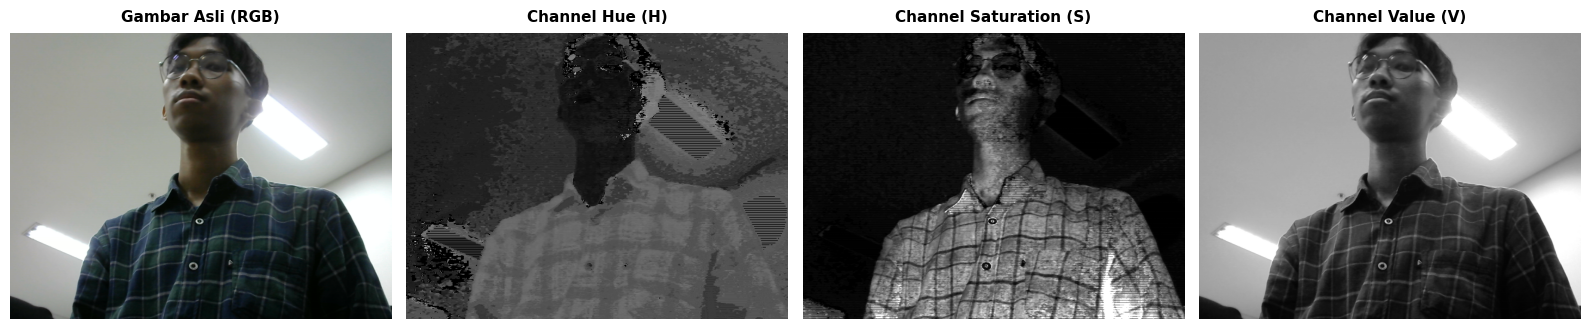

In [35]:
# Konversi frame dari BGR ke HSV
frame_hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

# Pisahkan channel Hue, Saturation, Value
h_channel, s_channel, v_channel = cv2.split(frame_hsv)

# Channel H, S, V adalah matriks 2D sehingga otomatis dirender dengan cmap='gray'
show(
    [frame_rgb, h_channel, s_channel, v_channel],
    ["Gambar Asli (RGB)", "Channel Hue (H)", "Channel Saturation (S)", "Channel Value (V)"],
    cols=4, size=(4, 4)
)

## 1.2 Thresholding: Binary Threshold vs HSV Range

### Konsep Dasar:
Thresholding mengubah citra bergradasi kontinu menjadi citra biner (`0` hitam, `255` putih). Citra biner ini berfungsi sebagai **mask** (stensil) pemisah objek dan latar belakang.

### Perbandingan Metode:
- **`cv2.threshold()` pada grayscale:** hanya $1$ channel, hanya intensitas total
  $$Y = 0.299R + 0.587G + 0.114B$$
  Dua warna berbeda (kulit subjek vs kain hijau) bisa punya abu-abu yang sama, sehingga **gagal memisahkan warna spesifik latar**.
- **`cv2.inRange(hsv, lower, upper)` pada HSV:** memeriksa $3$ channel sekaligus, apakah `lower <= pixel <= upper`. Dalam rentang pada semua channel menjadi `255`, selainnya `0`. **Presisi untuk mengisolasi green screen.**

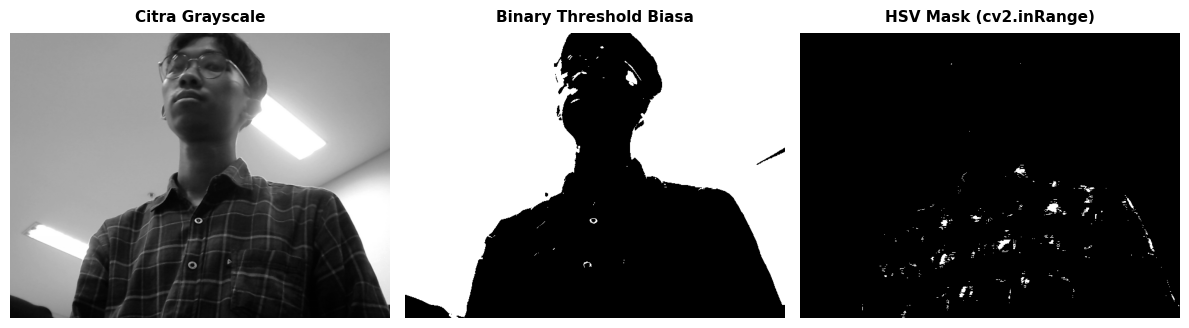

In [36]:
# 1. Binary Thresholding konvensional pada grayscale
gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
_, binary_thresh = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

# 2. Color Range Thresholding pada HSV dengan cv2.inRange
# Rentang hijau (Green Screen):
# - Hue: 35 s.d. 85 (hijau muda, hijau daun, hingga hijau toska)
# - Saturation: 50 s.d. 255 (menyaring putih/abu-abu netral)
# - Value: 50 s.d. 255 (menyaring area bayangan yang terlalu gelap)
lower_green = np.array([35, 50, 50])
upper_green = np.array([85, 255, 255])

# Panduan bila memakai latar warna lain:
# - Latar Biru  : lower = np.array([90, 50, 50]),   upper = np.array([130, 255, 255])
# - Latar Merah : lower = np.array([0, 70, 50]),    upper = np.array([10, 255, 255])

# Mask biner: area hijau = 255 (putih), selain hijau = 0 (hitam)
mask = cv2.inRange(frame_hsv, lower_green, upper_green)

show(
    [gray, binary_thresh, mask],
    ["Citra Grayscale", "Binary Threshold Biasa", "HSV Mask (cv2.inRange)"],
    cols=3, size=(4, 4)
)

## 1.3 Masking dan Operasi Bitwise

### Cara Kerja Mask Biner (gerbang logika per piksel):
- **`255` (putih / TRUE):** meloloskan piksel citra asli apa adanya.
- **`0` (hitam / FALSE):** menahan piksel sehingga menjadi `0` (hitam).

### Tahapan:
1. **`mask`:** latar lama `255`, subjek `0`. Dipakai memotong background baru agar hanya muncul di area latar hijau.
2. **`mask_inv = cv2.bitwise_not(mask)`:** dibalik ($255 - \text{mask}$), subjek `255`, latar `0`. Dipakai memotong subjek dari frame.
3. **`cv2.bitwise_and(src, src, mask=...)`:** mengekstrak piksel sesuai area putih pada mask.

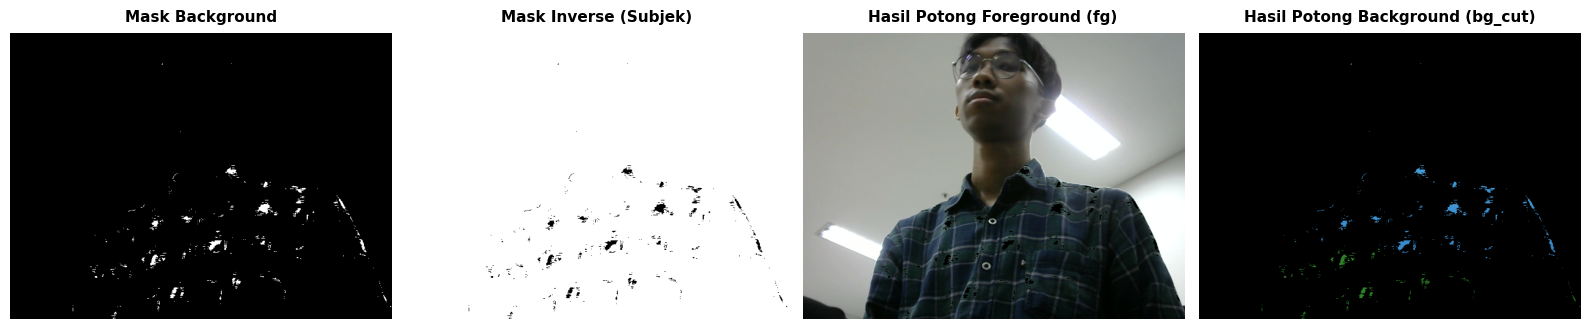

In [37]:
# 1. Mask inverse untuk mengisolasi subjek
mask_inv = cv2.bitwise_not(mask)

# 2. Foreground (subjek): piksel subjek lolos, area green screen menjadi hitam
fg = cv2.bitwise_and(frame_rgb, frame_rgb, mask=mask_inv)

# 3. Background baru dipotong sesuai bentuk area green screen
bg_cut = cv2.bitwise_and(bg_rgb, bg_rgb, mask=mask)

show(
    [mask, mask_inv, fg, bg_cut],
    ["Mask Background", "Mask Inverse (Subjek)", "Hasil Potong Foreground (fg)", "Hasil Potong Background (bg_cut)"],
    cols=4, size=(4, 4)
)

## 1.4 Penggabungan Akhir (Background Replacement)

Langkah terakhir pipeline chroma key adalah menjumlahkan `fg` dan `bg_cut`:
$$\text{Hasil Akhir} = \text{fg} + \text{bg\_cut}$$

- `fg`: area subjek berisi piksel subjek, area latar `0`.
- `bg_cut`: area subjek `0`, area latar berisi piksel background baru.
- Area subjek: $\text{Piksel Subjek} + 0 = \text{Piksel Subjek}$. Area latar: $0 + \text{Piksel Background Baru}$.

`cv2.add` dipakai (bukan operator `+` numpy) karena ia **saturasi** di 255, tidak *wrap-around*.

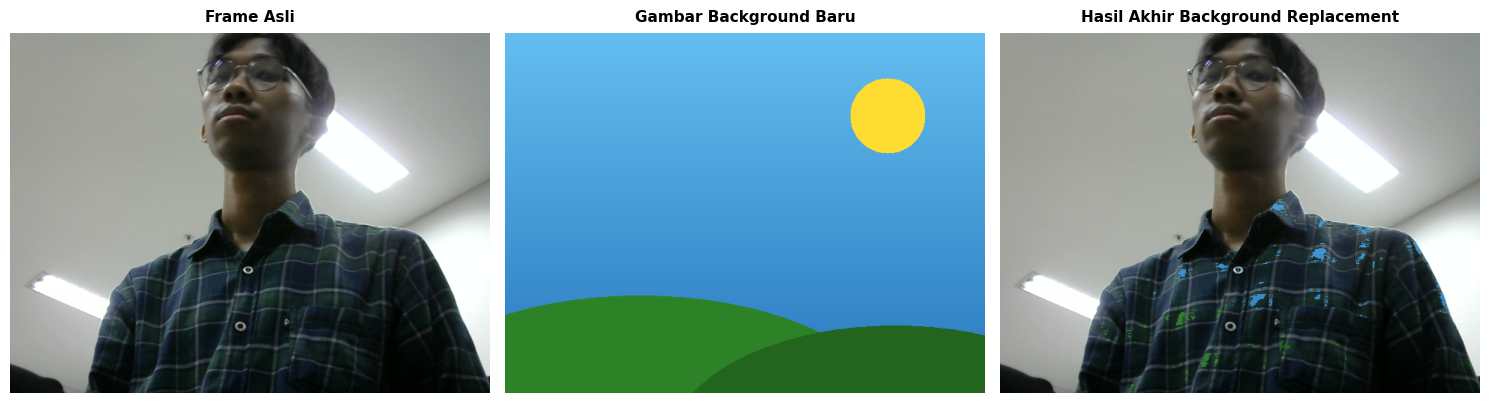

In [38]:
# Penggabungan akhir dengan cv2.add
final_result = cv2.add(fg, bg_cut)

show(
    [frame_rgb, bg_rgb, final_result],
    ["Frame Asli", "Gambar Background Baru", "Hasil Akhir Background Replacement"],
    cols=3, size=(5, 4)
)

## 1.5 Real-time Live Chroma Key (Webcam)

Fungsi `run_live_chroma_key()` menjalankan seluruh pipeline secara real-time frame-by-frame dengan `cv2.VideoCapture(0)` dan jendela `cv2.imshow()`. Tekan **`q`** pada jendela video untuk keluar.

> `cv2.imshow` butuh GUI desktop. Jalankan di VSCode / Jupyter lokal. Di server tanpa display (Colab, SSH tanpa X) fungsi ini tidak akan bekerja. Pada beberapa OS jendela dapat muncul di balik jendela VSCode.

In [39]:
def run_live_chroma_key(bg_path='background.jpg',
                        lower_hsv=np.array([35, 50, 50]),
                        upper_hsv=np.array([85, 255, 255])):
    """
    Background replacement (chroma key) real-time via webcam.
    Tekan tombol 'q' pada jendela OpenCV untuk keluar.
    """
    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        print("[ERROR] Webcam tidak dapat diakses.")
        return

    bg = cv2.imread(bg_path)

    print("[INFO] Live Chroma Key aktif. Tekan tombol 'q' di jendela video untuk berhenti.")

    while True:
        ret, live_frame = cap.read()
        if not ret:
            print("[WARNING] Gagal membaca frame dari webcam.")
            break

        h, w = live_frame.shape[:2]

        # Samakan ukuran background dengan frame webcam
        if bg is None or bg.shape[:2] != (h, w):
            if bg is not None:
                bg_resized = cv2.resize(bg, (w, h))
            else:
                # Background sintetis jika background.jpg belum tersedia
                bg_resized = np.zeros((h, w, 3), dtype=np.uint8)
                bg_resized[:, :] = [240, 180, 100]  # biru langit (BGR)
        else:
            bg_resized = bg

        # Pipeline Chroma Key
        hsv = cv2.cvtColor(live_frame, cv2.COLOR_BGR2HSV)                              # 1. BGR -> HSV
        live_mask = cv2.inRange(hsv, lower_hsv, upper_hsv)                             # 2. threshold warna latar
        live_mask_inv = cv2.bitwise_not(live_mask)                                     # 3. mask subjek
        live_fg = cv2.bitwise_and(live_frame, live_frame, mask=live_mask_inv)          # 4a. potong foreground
        live_bg_cut = cv2.bitwise_and(bg_resized, bg_resized, mask=live_mask)          # 4b. potong background
        live_final = cv2.add(live_fg, live_bg_cut)                                     # 5. gabungkan

        cv2.imshow("Live Chroma Key - IMV Laboratory (Tekan 'q' untuk keluar)", live_final)

        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    cap.release()
    cv2.destroyAllWindows()
    print("[INFO] Sesi Live Chroma Key selesai.")


# Hapus tanda komentar untuk menjalankan (akan membuka jendela webcam):
# run_live_chroma_key('background.jpg')

---
# BAGIAN 2 — Filtering dan Edge Detection

## 2.0 Persiapan Gambar Grayscale

Gambar otomatis diperkecil ke maksimal 256 piksel di sisi terpanjang lewat `resize_max`, supaya loop manual tidak terlalu lama. **Jangan masukkan gambar besar tanpa `resize_max`**: gambar 12 megapiksel bisa membuat satu sel berjalan berpuluh menit.

Ganti `IMAGE_PATH` dengan nama file gambarmu (letakkan di folder notebook). Jika file tidak ditemukan, otomatis dipakai gambar bawaan `skimage.data.camera()` dan `data.astronaut()`, jadi notebook tetap bisa dijalankan.

In [40]:
IMAGE_PATH = 'h2hjuun.jpg'   # ganti dengan file gambarmu, mis. 'gambarku.jpg'

(255, 184) uint8 0 254


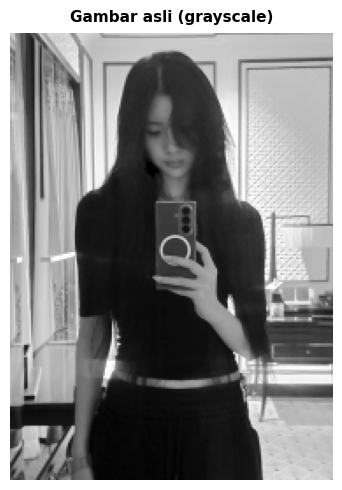

In [41]:
def load_image(path, color=False):
    """Baca gambar dari file; bila tidak ada, pakai gambar contoh skimage. Hasil: grayscale uint8 atau RGB."""
    im = cv2.imread(path) if os.path.exists(path) else None
    if im is None:
        print(f"[INFO] '{path}' tidak ditemukan, memakai gambar contoh skimage.")
        return data.astronaut() if color else data.camera()
    if color:
        return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
    return cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)


img = resize_max(load_image(IMAGE_PATH))  # grayscale uint8
print(img.shape, img.dtype, img.min(), img.max())

show([img], ['Gambar asli (grayscale)'], cols=1, size=(5, 5))

## 2.1 Konvolusi 2D Manual Pakai Loop

Untuk setiap piksel (y, x), geser kernel ke atas piksel itu, kalikan elemen yang bersesuaian, lalu jumlahkan.

Poin penting:
- **Padding** supaya piksel pinggir tetap punya tetangga (zero, replicate, reflect)
- **Flip kernel** untuk konvolusi sejati (tanpa flip, itu korelasi)
- **Float64** untuk hasil antara, lalu clip saat ditampilkan

In [42]:
@njit
def _convolve_loops(padded, flipped, h, w):
    # Inti konvolusi: 4 loop bersarang (di-compile numba jika tersedia)
    kh, kw = flipped.shape
    out = np.zeros((h, w), dtype=np.float64)
    for y in range(h):
        for x in range(w):
            s = 0.0
            for i in range(kh):
                for j in range(kw):
                    s += padded[y + i, x + j] * flipped[i, j]
            out[y, x] = s
    return out


def convolve2d(image, kernel, padding='reflect'):
    image = image.astype(np.float64)
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2

    mode = {'zero': 'constant', 'replicate': 'edge', 'reflect': 'reflect'}[padding]
    padded = np.pad(image, ((ph, ph), (pw, pw)), mode=mode)

    flipped = np.ascontiguousarray(np.flipud(np.fliplr(kernel)), dtype=np.float64)  # konvolusi = korelasi dgn kernel di-flip

    h, w = image.shape
    return _convolve_loops(padded, flipped, h, w)

### Verifikasi terhadap OpenCV

`cv2.filter2D` sebenarnya menghitung **korelasi**, jadi untuk membandingkan dengan konvolusi sejati kernel perlu di-flip dulu. `np.pad(mode='reflect')` setara dengan `cv2.BORDER_REFLECT_101`.

Selisih maksimum manual vs OpenCV: 0.00e+00
Waktu manual : 0.000 s
Waktu OpenCV : 0.00102 s  (sekitar 0x lebih cepat)


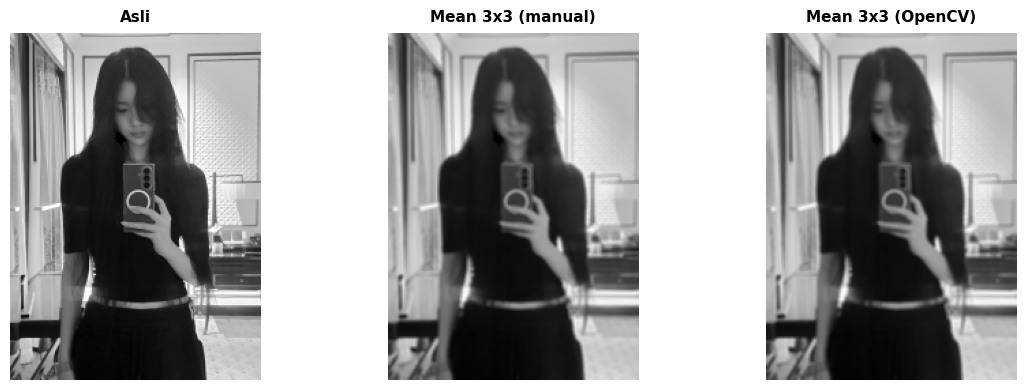

In [43]:
k_mean = np.ones((3, 3)) / 9.0
convolve2d(img[:8, :8], k_mean)  # pemanasan: pemanggilan pertama ikut mengompilasi (numba), jangan diukur

t0 = time.time()
manual = convolve2d(img, k_mean, padding='reflect')
t_manual = time.time() - t0

t0 = time.time()
ref = cv2.filter2D(img.astype(np.float64), -1, np.flipud(np.fliplr(k_mean)),
                   borderType=cv2.BORDER_REFLECT_101)
t_cv = time.time() - t0

print(f'Selisih maksimum manual vs OpenCV: {np.abs(manual - ref).max():.2e}')
print(f'Waktu manual : {t_manual:.3f} s')
print(f'Waktu OpenCV : {t_cv:.5f} s  (sekitar {t_manual / max(t_cv, 1e-9):.0f}x lebih cepat)')

show([img, to_uint8(manual), to_uint8(ref)], ['Asli', 'Mean 3x3 (manual)', 'Mean 3x3 (OpenCV)'])

### Pengaruh border handling

Perhatikan tepi gambar. Zero padding membuat tepi menggelap karena tetangga di luar gambar dianggap 0.

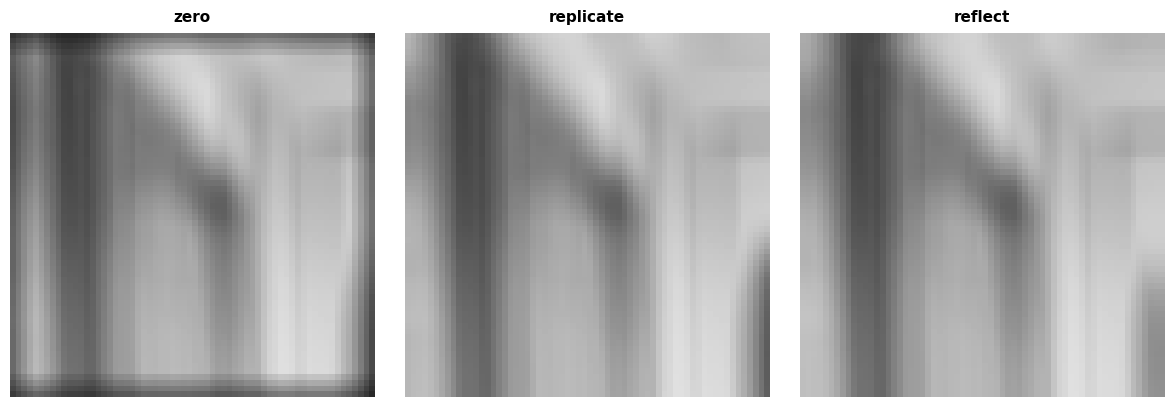

In [44]:
k_big = np.ones((9, 9)) / 81.0  # kernel besar supaya efek tepi jelas
small = img[:64, :64]           # potongan kecil agar cepat

res = [convolve2d(small, k_big, padding=p) for p in ['zero', 'replicate', 'reflect']]
show([to_uint8(r) for r in res], ['zero', 'replicate', 'reflect'])

## 2.2 Filtering

Siapkan dulu dua jenis noise: Gaussian noise dan salt-and-pepper.

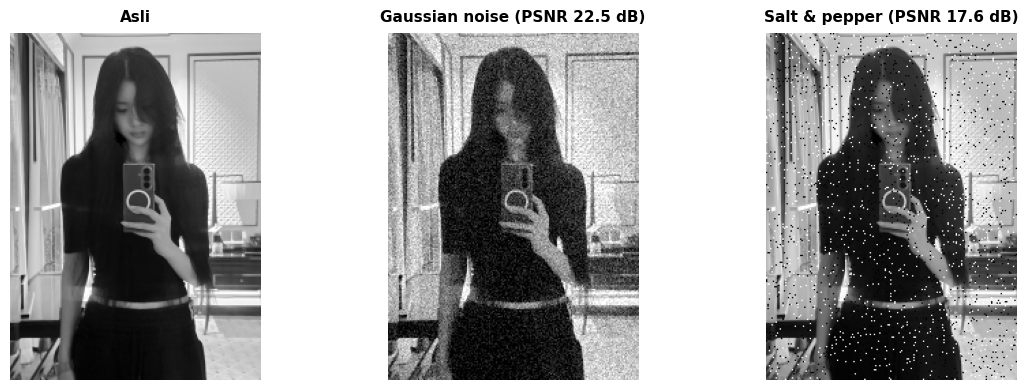

In [45]:
def add_gaussian_noise(image, sigma=20):
    return to_uint8(image + rng.normal(0, sigma, image.shape))


def add_salt_pepper(image, amount=0.05):
    out = image.copy()
    r = rng.random(image.shape)
    out[r < amount / 2] = 0
    out[r > 1 - amount / 2] = 255
    return out


noisy_g = add_gaussian_noise(img, sigma=20)
noisy_sp = add_salt_pepper(img, amount=0.05)

show([img, noisy_g, noisy_sp],
     ['Asli', f'Gaussian noise (PSNR {psnr(img, noisy_g):.1f} dB)',
      f'Salt & pepper (PSNR {psnr(img, noisy_sp):.1f} dB)'])

### 2.2.1 Mean dan Gaussian filter (linear, low-pass)

Kernel Gaussian dibuat sendiri dari rumus, lalu dinormalisasi supaya jumlah bobot = 1.

In [46]:
def gaussian_kernel(size=5, sigma=1.0):
    ax = np.arange(size) - size // 2
    xx, yy = np.meshgrid(ax, ax)
    k = np.exp(-(xx ** 2 + yy ** 2) / (2 * sigma ** 2))
    return k / k.sum()


print(np.round(gaussian_kernel(5, 1.0), 4))
print('Jumlah bobot:', gaussian_kernel(5, 1.0).sum())

[[0.003  0.0133 0.0219 0.0133 0.003 ]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.0219 0.0983 0.1621 0.0983 0.0219]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.003  0.0133 0.0219 0.0133 0.003 ]]
Jumlah bobot: 1.0


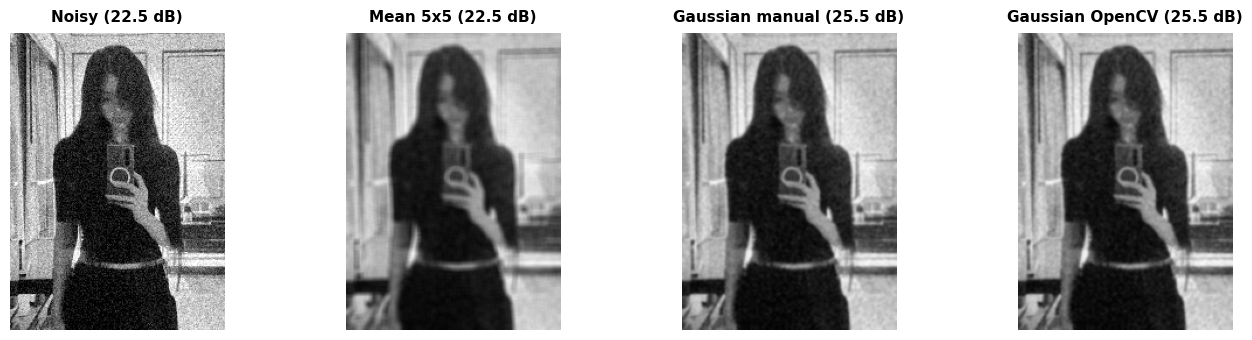

In [47]:
mean_out = to_uint8(convolve2d(noisy_g, np.ones((5, 5)) / 25.0))
gauss_out = to_uint8(convolve2d(noisy_g, gaussian_kernel(5, 1.0)))
gauss_cv = cv2.GaussianBlur(noisy_g, (5, 5), 1.0)

show([noisy_g, mean_out, gauss_out, gauss_cv],
     [f'Noisy ({psnr(img, noisy_g):.1f} dB)',
      f'Mean 5x5 ({psnr(img, mean_out):.1f} dB)',
      f'Gaussian manual ({psnr(img, gauss_out):.1f} dB)',
      f'Gaussian OpenCV ({psnr(img, gauss_cv):.1f} dB)'], cols=4, size=(3.5, 3.5))

**Eksperimen:** coba ubah `sigma` (0.5, 1, 2, 3) dan ukuran kernel. Apa yang terjadi pada noise dan ketajaman detail?

### 2.2.2 Median filter (non-linear)

Median tidak bisa ditulis sebagai konvolusi, karena hasilnya bukan jumlah berbobot. Di sini kita ambil nilai tengah dari jendela. Bandingkan dengan mean pada salt-and-pepper.

Median manual sama dengan OpenCV: True


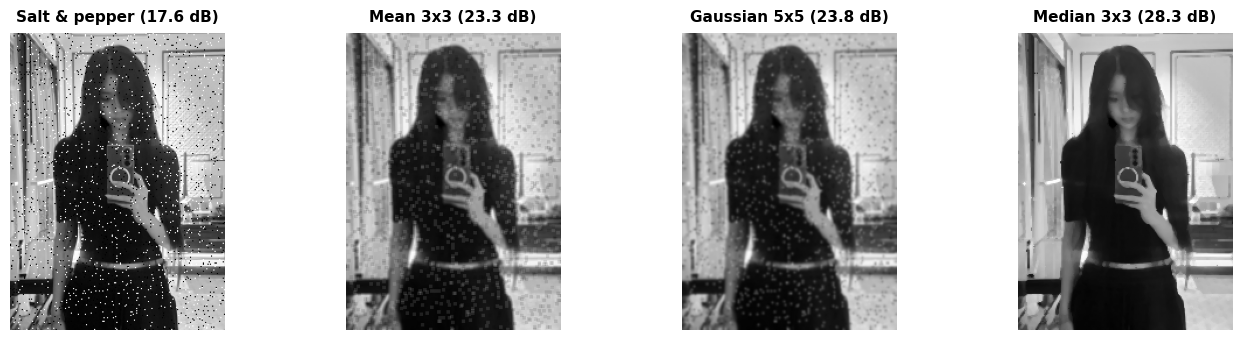

In [48]:
@njit
def _median_loops(padded, size, h, w):
    out = np.zeros((h, w), dtype=padded.dtype)
    for y in range(h):
        for x in range(w):
            window = padded[y:y + size, x:x + size]
            out[y, x] = np.median(window.ravel())
    return out


def median_filter(image, size=3):
    p = size // 2
    padded = np.ascontiguousarray(np.pad(image, p, mode='edge'))  # replicate, sama seperti cv2.medianBlur
    h, w = image.shape
    return _median_loops(padded, size, h, w)


sp_mean = to_uint8(convolve2d(noisy_sp, np.ones((3, 3)) / 9.0))
sp_gauss = to_uint8(convolve2d(noisy_sp, gaussian_kernel(5, 1.0)))
sp_median = median_filter(noisy_sp, 3)
sp_median_cv = cv2.medianBlur(noisy_sp, 3)

print('Median manual sama dengan OpenCV:', np.array_equal(sp_median, sp_median_cv))

show([noisy_sp, sp_mean, sp_gauss, sp_median],
     [f'Salt & pepper ({psnr(img, noisy_sp):.1f} dB)',
      f'Mean 3x3 ({psnr(img, sp_mean):.1f} dB)',
      f'Gaussian 5x5 ({psnr(img, sp_gauss):.1f} dB)',
      f'Median 3x3 ({psnr(img, sp_median):.1f} dB)'], cols=4, size=(3.5, 3.5))

### 2.2.3 Sharpening

Dua cara: kernel sharpening langsung, dan unsharp masking (`asli + amount * (asli - blur)`).

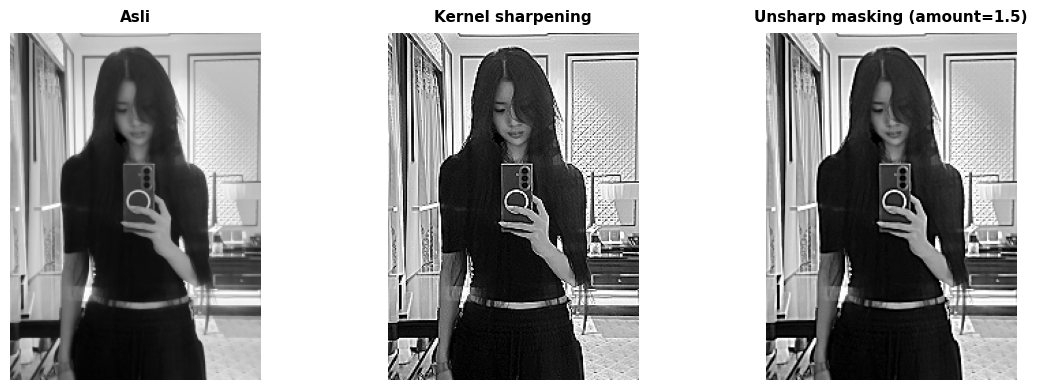

In [49]:
k_sharp = np.array([[0, -1, 0],
                    [-1, 5, -1],
                    [0, -1, 0]], dtype=np.float64)
sharp_kernel = to_uint8(convolve2d(img, k_sharp))

blurred = convolve2d(img, gaussian_kernel(5, 1.5))
unsharp = to_uint8(img + 1.5 * (img - blurred))

show([img, sharp_kernel, unsharp], ['Asli', 'Kernel sharpening', 'Unsharp masking (amount=1.5)'])

## 2.3 Edge Detection

### 2.3.1 Sobel dan Prewitt (turunan orde pertama)

Hitung Gx dan Gy dengan konvolusi, lalu magnitude `sqrt(Gx^2 + Gy^2)` dan arah `atan2(Gy, Gx)`.

Catatan: karena `convolve2d` melakukan flip kernel, tanda Gx/Gy bisa terbalik dibanding korelasi. Magnitude tidak terpengaruh, arah hanya bergeser 180 derajat.

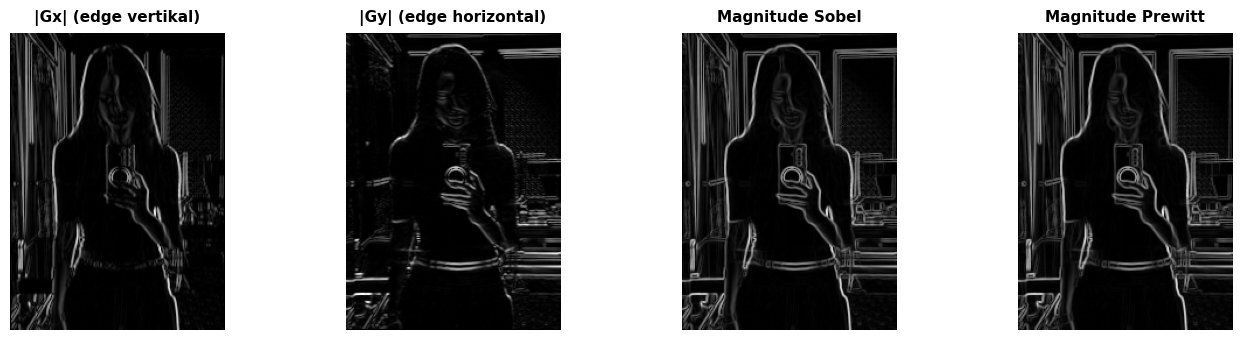

In [50]:
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype=np.float64)
sobel_y = sobel_x.T

prewitt_x = np.array([[-1, 0, 1],
                      [-1, 0, 1],
                      [-1, 0, 1]], dtype=np.float64)
prewitt_y = prewitt_x.T


def gradient(image, kx, ky):
    gx = convolve2d(image, kx)
    gy = convolve2d(image, ky)
    mag = np.hypot(gx, gy)
    ang = np.arctan2(gy, gx)
    return gx, gy, mag, ang


gx, gy, mag_s, ang_s = gradient(img, sobel_x, sobel_y)
_, _, mag_p, _ = gradient(img, prewitt_x, prewitt_y)

show([normalize_to_uint8(np.abs(gx)), normalize_to_uint8(np.abs(gy)),
      normalize_to_uint8(mag_s), normalize_to_uint8(mag_p)],
     ['|Gx| (edge vertikal)', '|Gy| (edge horizontal)', 'Magnitude Sobel', 'Magnitude Prewitt'],
     cols=4, size=(3.5, 3.5))

Bandingkan dengan `cv2.Sobel`, lalu terapkan threshold pada magnitude untuk mendapat peta edge biner.

Selisih magnitude manual vs cv2.Sobel: 0.00e+00


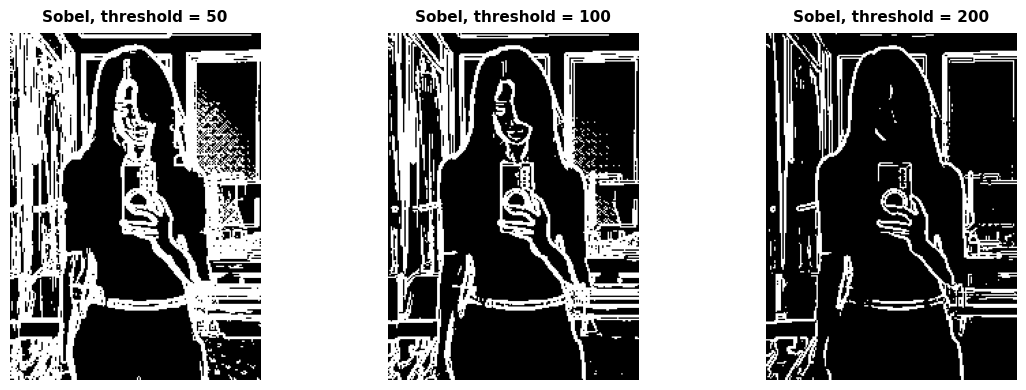

In [51]:
cx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
cy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
mag_cv = np.hypot(cx, cy)
print(f'Selisih magnitude manual vs cv2.Sobel: {np.abs(mag_s - mag_cv).max():.2e}')

thresholds = [50, 100, 200]
show([((mag_s > t) * 255).astype(np.uint8) for t in thresholds],
     [f'Sobel, threshold = {t}' for t in thresholds])

### 2.3.2 Pengaruh noise terhadap edge detection

Turunan memperbesar noise. Lihat bedanya Sobel pada gambar noisy tanpa dan dengan blur Gaussian terlebih dahulu.

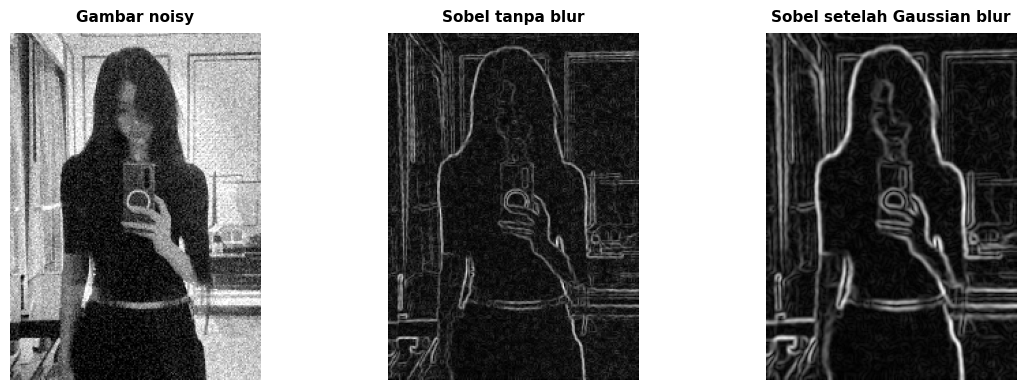

In [52]:
_, _, mag_noisy, _ = gradient(noisy_g, sobel_x, sobel_y)

smoothed = convolve2d(noisy_g, gaussian_kernel(5, 1.2))
_, _, mag_smooth, _ = gradient(smoothed, sobel_x, sobel_y)

show([noisy_g, normalize_to_uint8(mag_noisy), normalize_to_uint8(mag_smooth)],
     ['Gambar noisy', 'Sobel tanpa blur', 'Sobel setelah Gaussian blur'])

### 2.3.3 Laplacian dan LoG (turunan orde kedua)

Laplacian sangat sensitif noise, jadi dipasangkan dengan Gaussian (LoG). Edge dicari di titik **zero-crossing**, yaitu tempat nilai berganti tanda.

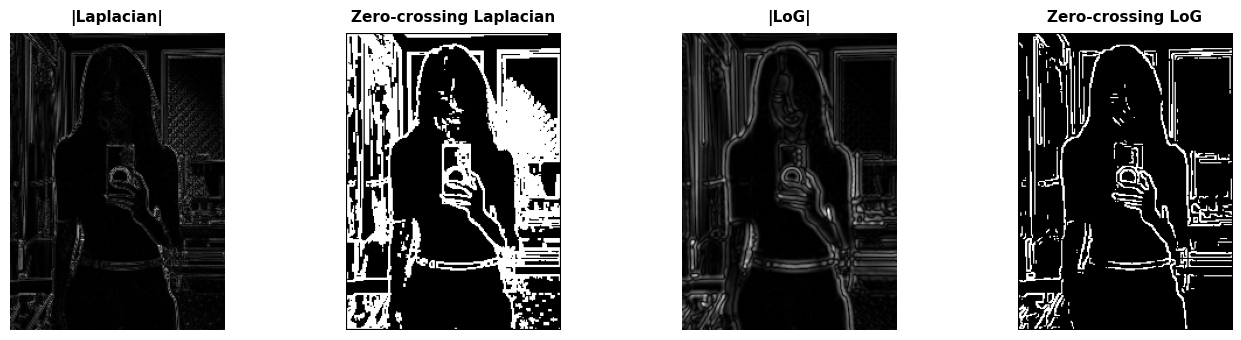

In [53]:
k_lap = np.array([[0, 1, 0],
                  [1, -4, 1],
                  [0, 1, 0]], dtype=np.float64)


@njit
def zero_crossing(lap, thr=5.0):
    out = np.zeros(lap.shape, dtype=np.uint8)
    h, w = lap.shape
    for y in range(1, h - 1):
        for x in range(1, w - 1):
            patch = lap[y - 1:y + 2, x - 1:x + 2]
            if patch.max() > thr and patch.min() < -thr:
                out[y, x] = 255
    return out


lap_raw = convolve2d(img, k_lap)
log_resp = convolve2d(convolve2d(img, gaussian_kernel(7, 1.4)), k_lap)

show([normalize_to_uint8(np.abs(lap_raw)), zero_crossing(lap_raw, 20),
      normalize_to_uint8(np.abs(log_resp)), zero_crossing(log_resp, 5)],
     ['|Laplacian|', 'Zero-crossing Laplacian', '|LoG|', 'Zero-crossing LoG'],
     cols=4, size=(3.5, 3.5))

### 2.3.4 Canny (OpenCV)

Tahapan internal: Gaussian blur, gradien, non-maximum suppression, double threshold, hysteresis. Di sini kita pakai `cv2.Canny` dan eksperimen dengan dua threshold-nya.

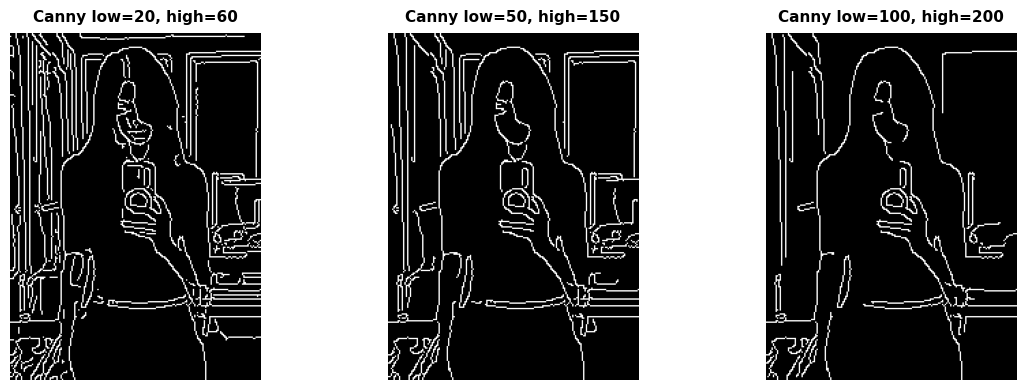

In [54]:
blur = cv2.GaussianBlur(img, (5, 5), 1.4)

params = [(20, 60), (50, 150), (100, 200)]
show([cv2.Canny(blur, lo, hi) for lo, hi in params],
     [f'Canny low={lo}, high={hi}' for lo, hi in params])

## 2.4 Perbandingan Akhir pada Gambar ber-noise

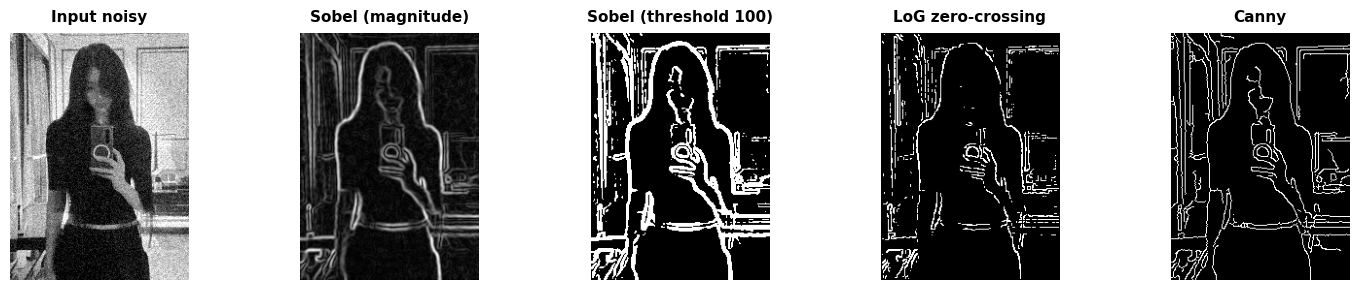

In [55]:
blur_n = cv2.GaussianBlur(noisy_g, (5, 5), 1.4)

sobel_result = normalize_to_uint8(mag_smooth)
sobel_binary = ((mag_smooth > 100) * 255).astype(np.uint8)
canny_result = cv2.Canny(blur_n, 50, 150)
log_result = zero_crossing(convolve2d(convolve2d(noisy_g, gaussian_kernel(7, 1.4)), k_lap), 8)

show([noisy_g, sobel_result, sobel_binary, log_result, canny_result],
     ['Input noisy', 'Sobel (magnitude)', 'Sobel (threshold 100)', 'LoG zero-crossing', 'Canny'],
     cols=5, size=(3, 3))

---
# BAGIAN 3 — Bonus: Hapus Background

Tiga pendekatan klasik, dari yang paling sederhana ke yang paling kuat. Semuanya berujung pada **mask biner** (putih = objek, hitam = background), lalu mask dipakai untuk memotong gambar. Ini menyatukan dua bagian sebelumnya: thresholding dan masking (Bagian 1) serta filtering dan edge detection (Bagian 2).

| Metode | Ide | Cocok untuk |
|---|---|---|
| A. Threshold (Otsu) | pisahkan berdasar terang/gelap | objek kontras jelas dengan background polos |
| B. Edge + contour | Canny, tutup celah, isi kontur terbesar | objek dengan tepi tegas dan background bersih |
| C. GrabCut | model warna foreground vs background, dioptimasi iteratif | gambar umum (pakai kotak di sekitar objek) |

Bagian ini memakai gambar **berwarna**. `cv2.imread(...)` menghasilkan BGR, jadi diubah ke RGB dengan `cv2.cvtColor(x, cv2.COLOR_BGR2RGB)` (sudah ditangani oleh `load_image(..., color=True)`).

In [56]:
img_color = load_image(IMAGE_PATH, color=True)   # RGB
gray_c = cv2.cvtColor(img_color, cv2.COLOR_RGB2GRAY)
blur_c = cv2.GaussianBlur(gray_c, (5, 5), 0)  # filtering dulu, seperti di materi
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))


def largest_component(mask):
    # Simpan hanya bagian putih terbesar (buang bintik-bintik kecil)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    if n <= 1:
        return mask
    k = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    return ((lab == k) * 255).astype(np.uint8)


def apply_mask(image, mask, bg=255):
    # Objek dipertahankan, background diganti warna bg (255 = putih)
    return np.where(mask[..., None] > 0, image, bg).astype(np.uint8)


show_color = show  # alias: show() sudah menangani citra 2D maupun RGB

### 3.A Threshold (Otsu) + morfologi

Otsu mencari nilai threshold otomatis. Morfologi *close* menutup lubang kecil, *open* membuang bintik. Metode ini hanya melihat **terang/gelap**, jadi gagal kalau objek dan background punya rentang kecerahan yang bercampur.

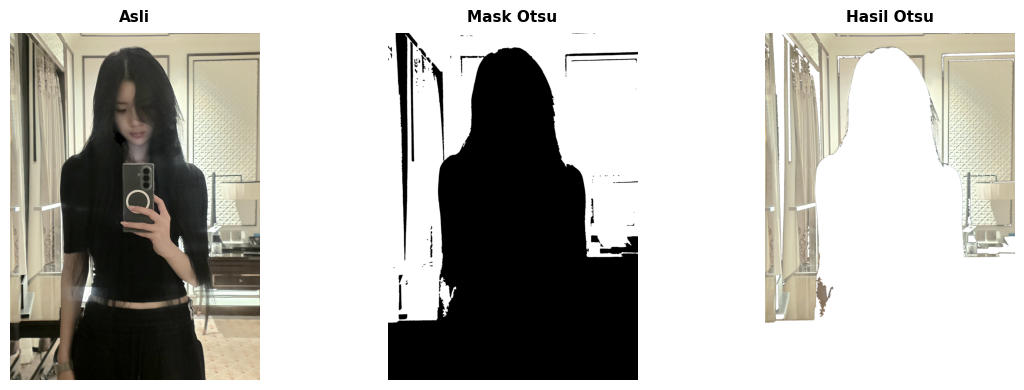

In [57]:
_, th = cv2.threshold(blur_c, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
th = cv2.morphologyEx(th, cv2.MORPH_CLOSE, kernel)
th = cv2.morphologyEx(th, cv2.MORPH_OPEN, kernel)
mask_otsu = largest_component(th)

show([img_color, mask_otsu, apply_mask(img_color, mask_otsu)],
     ['Asli', 'Mask Otsu', 'Hasil Otsu'], cols=3)

### 3.B Edge detection (Canny) + contour

Tepi dari Canny sering putus-putus, jadi di-*dilate* dulu supaya tersambung. Lalu kontur luar terbesar diisi penuh menjadi mask. Berhasil bila tepi objek jelas dan tidak banyak tepi lain di background.

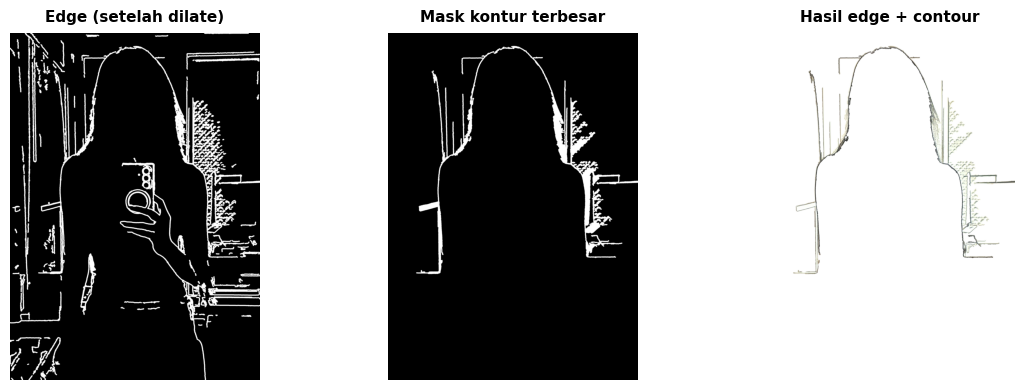

In [58]:
edges = cv2.Canny(blur_c, 50, 150)
edges = cv2.dilate(edges, kernel, iterations=2)
contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

mask_edge = np.zeros_like(gray_c)
cv2.drawContours(mask_edge, [max(contours, key=cv2.contourArea)], -1, 255, cv2.FILLED)

show([edges, mask_edge, apply_mask(img_color, mask_edge)],
     ['Edge (setelah dilate)', 'Mask kontur terbesar', 'Hasil edge + contour'], cols=3)

### 3.C GrabCut

GrabCut butuh **kotak (rect)** yang melingkupi objek: semua di luar kotak pasti background, di dalamnya diperkirakan sendiri lewat model warna (GMM) dan graph cut. Atur `rect = (x, y, lebar, tinggi)` sesuai gambarmu.

Nilai mask GrabCut: 0 = background pasti, 1 = foreground pasti, 2 = kemungkinan background, 3 = kemungkinan foreground.

Ukuran gambar: 2873 x 3993


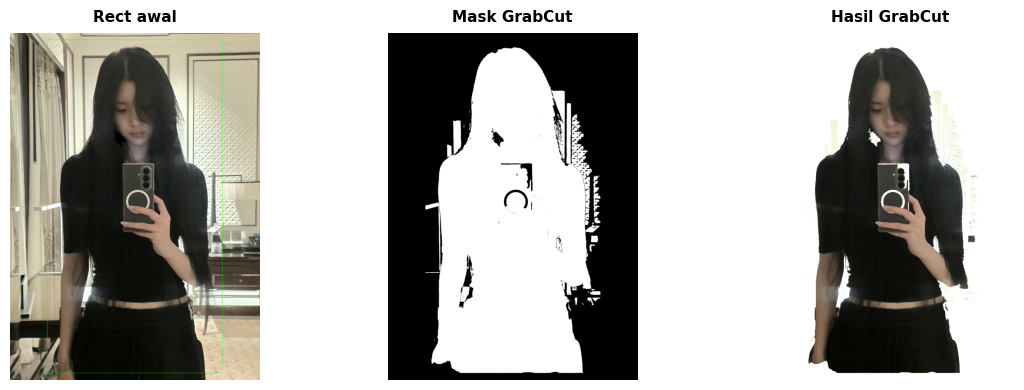

In [59]:
h, w = img_color.shape[:2]
print('Ukuran gambar:', w, 'x', h)

# (x, y, lebar, tinggi) sebagai pecahan dari ukuran gambar
rect = (int(0.15 * w), int(0.02 * h), int(0.70 * w), int(0.96 * h))

gc_mask = np.zeros(gray_c.shape, np.uint8)
bgd_model = np.zeros((1, 65), np.float64)
fgd_model = np.zeros((1, 65), np.float64)

bgr = cv2.cvtColor(img_color, cv2.COLOR_RGB2BGR)  # grabCut tidak peduli urutan kanal, ini untuk konsistensi
cv2.grabCut(bgr, gc_mask, rect, bgd_model, fgd_model, 5, cv2.GC_INIT_WITH_RECT)

mask_gc = np.where((gc_mask == 1) | (gc_mask == 3), 255, 0).astype(np.uint8)

preview = img_color.copy()
x, y, w, h = rect
cv2.rectangle(preview, (x, y), (x + w, y + h), (0, 255, 0), 2)

show([preview, mask_gc, apply_mask(img_color, mask_gc)],
     ['Rect awal', 'Mask GrabCut', 'Hasil GrabCut'], cols=3)

### Hasil akhir: PNG transparan dan ganti background

Mask dijadikan **alpha channel** supaya background benar-benar transparan, bukan sekadar putih. Mask juga di-blur sedikit supaya tepinya halus (ini lagi-lagi filtering).

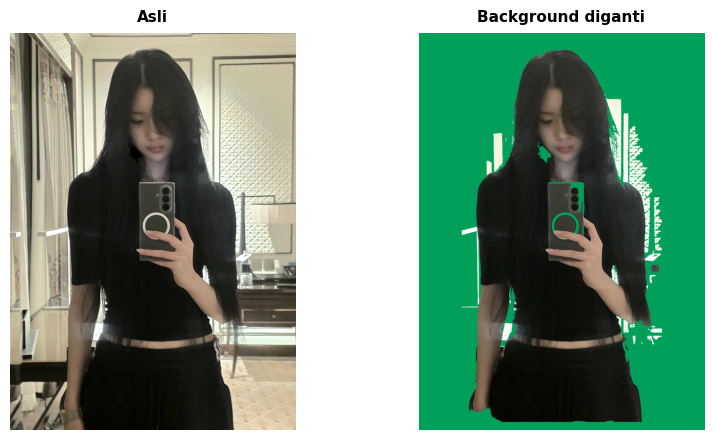

Tersimpan: hasil_tanpa_background.png


In [60]:
soft = cv2.GaussianBlur(mask_gc, (5, 5), 0)  # tepi halus

rgba = np.dstack([img_color, soft])           # RGB + alpha
cv2.imwrite('hasil_tanpa_background.png', cv2.cvtColor(rgba, cv2.COLOR_RGBA2BGRA))

# Ganti dengan background warna lain (alpha blending)
alpha = (soft / 255.0)[..., None]
green = np.full_like(img_color, (0, 160, 90))
composite = (alpha * img_color + (1 - alpha) * green).astype(np.uint8)

show([img_color, composite], ['Asli', 'Background diganti'], cols=2, size=(4.5, 4.5))
print('Tersimpan: hasil_tanpa_background.png')

> **Kalau hasilnya masih kurang bagus:** untuk gambar yang rumit (rambut, bulu, background ramai), metode klasik ada batasnya. Alternatif berbasis deep learning: `pip install rembg`, lalu
> `from rembg import remove; hasil = remove(gambar_pil)`. Tidak butuh rect atau tuning, tapi mengunduh model saat pertama kali dipakai dan lebih berat.